![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 1. Waveguides

Welcome to our Photonic Integrated Circuits Laboratory! Throughout the course, we will be using a Python package called [GDSFactory](https://gdsfactory.github.io/gdsfactory/index.html). This is an open-source tool, and is a great alternative to other commercial software like Synopsys Optodesigner, Luceda Photonics, or Lumerical/Interconnect. Since it runs on Python, you have two options for executing your laboratory tasks:

1. **Local installation on your own PC** (Recommended): Please note that we will not spend class time on installing the software. However, feel free to reach out if you need help with the installation.

2. **Cloud Workspace**: Alternatively, you can use a cloud-based solution if the Local installation does not work.

## 0. Imports

For this laboratory you will need the following libraries:

In [65]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td

import gplugins as gp
import gplugins.tidy3d as gt
from gplugins import plot
from gplugins.common.config import PATH

import pandas as pd

nm = 1e-3
wavelength = np.linspace(1500, 1600,11) * nm
f = td.C_0 / wavelength
c = 3e+8 # m/s
print(f'c = {td.C_0:.3e} um/s') # um/s

c = 2.998e+14 um/s


In [80]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)

# for the extra part
si_complex = td.material_library["cSi"]["Li1993_293K"].eps_model(f)
si_index , si_k = td.Medium.eps_complex_to_nk(si_complex)

## LO.1. Effective index of a waveguide - Convergence Tests

We have asumed until now, that the **real** value of the effective index for each cross-section is the value provided by this mode-solver. However, this number relies on a numerical method, making it sensible to some input parameters, such as the selected grid. The objective of this section is to find the dependence of the **calculated** value of the effective index with the *grid_resolution* and the *max_grid_scaling*, the two parameters that we can modify from the automatic grid function used at the gt.modes.Waveguide() function.  <br>
- Consider a 1.2 um width deep waveguide (SiNx), with 0.3 um height operating at 1550 nm.
    - Sweep the *grid_resolution* between 10 and 100 in steps of 10. Plot the **calculated** effective index vs the *grid_resolution*. 
    - Select a value for the *grid_resolution* from the latter sweep (where the calculated index remains almost constant), and sweep the *max_grid_scaling* from 1.2 to 1.6 in steps of 0.1. Plot the **calculated** effective index vs the *max_grid_scaling*.
    - Conclude which will be the best configuration for the grid parameters for this particular case. 

### LO.1.1 Grid resolution sweep

We can do the convergence tests for just the fundamental mode --> num_modes=1 at deep_waveguide arguments.

In [194]:
%%capture

g_res_1 = np.linspace(10, 100, 19) # pasos de 5
g_res_2 = np.linspace(10, 100, 10) # pasos de 10

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

# el sweep de n_eff podem fer-lo per al mode fonamental només
sweep_neff_1 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  grid_resolution=g_res_1)

sweep_neff_2 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  grid_resolution=g_res_2)

2026-11-09 19:30:15.557 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_09770a5eb4303d37.npz.
2026-11-09 19:30:15.655 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c54984b55de6893d.npz.
2026-11-09 19:30:15.686 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_972b4c36731994ce.npz.
2026-11-09 19:30:15.714 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e24360bf8970f801.npz.
2026-11-09 19:30:15.737 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4aa1037aeb7bae0f.npz.
2026-11-09 19:30:15.756 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4cff7a13712cd2b2.npz.
2026-11-09 19:30:15.781 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4a7cfe924ea84b0e.npz.
2026-11-09 19:30:15.803 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4490d65ca4f86b21.npz.


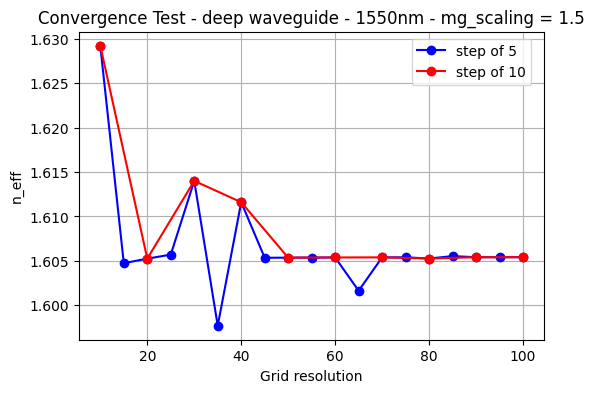

In [195]:
plt.figure(figsize=(6, 4))
plt.plot(g_res_1,sweep_neff_1.real,'bo-',label='step of 5')
plt.plot(g_res_2,sweep_neff_2.real,'ro-',label='step of 10')
plt.title("Convergence Test - deep waveguide - 1550nm - mg_scaling = 1.5")
plt.xlabel("Grid resolution")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(0.7,1))

### LO1.2 Max grid scaling sweep

We can fisrt try with grid_resolution = 20, 'cause it is the least computational demanding value that seems to achieve a n_eff value similar to the "convergent" one.

In [ ]:
%%capture
mg_scaling_1 = np.linspace(1.2, 1.6, 5) # pasos de 0.1
mg_scaling_2 = np.linspace(1.2, 1.6, 9) # pasos de 0.05

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

# el sweep de n_eff podem fer-lo per al mode fonamental només
sweep_neff_1 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_1)

sweep_neff_2 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_2)

In [ ]:

plt.figure(figsize=(6, 4))
plt.plot(mg_scaling_1,sweep_neff_1.real,'bo-',label='step of 0.1')
plt.plot(mg_scaling_2,sweep_neff_2.real,'ro-',label='step of 0.05')
plt.title("Convergence Test - deep waveguide - 1550nm - grid res = 20")
plt.xlabel("Max grid scaling")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(0.7,1))

We then must try with grid_resolution = 60, which gives already a stable n_eff value.

In [ ]:
%%capture
mg_scaling_1 = np.linspace(1.2, 1.6, 5) # pasos de 0.1
mg_scaling_2 = np.linspace(1.2, 1.6, 9) # pasos de 0.05

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=60, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

# el sweep de n_eff podem fer-lo per al mode fonamental només
sweep_neff_1 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_1)

sweep_neff_2 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_2)



In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(mg_scaling_1,sweep_neff_1.real,'bo-',label='step of 0.1')
plt.plot(mg_scaling_2,sweep_neff_2.real,'ro-',label='step of 0.05')
plt.title("Convergence Test - deep waveguide - 1550nm - grid res = 60")
plt.xlabel("Max grid scaling")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(0.7,1))

We can look at the results of grid_resolution = 100. Probably, a value of grid_res as HIGH as this one will allow us to take a smaller value of max_grid_scaling. In other words, the convergence will be faster. However, computational time will skyrocket.  

In [ ]:
mg_scaling_1 = np.linspace(1.2, 1.6, 5) # pasos de 0.1
mg_scaling_2 = np.linspace(1.2, 1.6, 9) # pasos de 0.05

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=100, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

# el sweep de n_eff podem fer-lo per al mode fonamental només
sweep_neff_1 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_1)

sweep_neff_2 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_2)

plt.figure(figsize=(6, 4))
plt.plot(mg_scaling_1,sweep_neff_1.real,'bo-',label='step of 0.1')
plt.plot(mg_scaling_2,sweep_neff_2.real,'ro-',label='step of 0.05')
plt.title("Convergence Test - deep waveguide - 1550nm - grid res = 100")
plt.xlabel("Max grid scaling")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(0.7,1))
print(sweep_neff_1)
print(sweep_neff_2)

We must highlight that the convergence of max_grid_scaling varies depending on the grid_resolution value, and specially, that the n_eff value at which the data stabilizes isn't the same for every one.

### L01.2 Doble sweep

We can try to summ up the both convergence test in one plot by sweeping at the same time grid_Resolution and max_grid_scaling. We will do it both times but exchanging the orther.

For the sweep, the arguments we pass to the function gt.modes.sweep_n_eff() must be always arrays. If we pass two arguments, the function will evaluate n_eff for every combination, returning a list with shape (len(arg. 1), len(arg. 2)).

In [ ]:
%%capture
g_res = np.linspace(10, 100, 10) # pasos de 10
mg_scaling = np.linspace(1.2, 1.6, 5) # pasos de 0.1

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

sweep = gt.modes.sweep_n_eff(deep_waveguide, grid_resolution=g_res, max_grid_scaling=mg_scaling)

In [ ]:
plt.figure(figsize=(6, 4))
for k in range(sweep.shape[1]):
    plt.plot(g_res,sweep[:,k].real,'o--',label=f'mg_scaling={mg_scaling[k]}')

plt.title("Convergence Test - deep waveguide - 1550nm")
plt.xlabel("Grid resolution")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper center')
print(sweep.real)

Based on this figure, a good pair of grid parameters would be {grid_resolution > 50, max_grid_scaling > 1.5}

In [ ]:
%%capture
g_res = np.array([20, 60, 80, 100]) # pasos de 10
mg_scaling = np.linspace(1.2, 1.6, 9) # pasos de 0.05

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

sweep = gt.modes.sweep_n_eff(deep_waveguide, grid_resolution=g_res, max_grid_scaling=mg_scaling)

In [ ]:
plt.figure(figsize=(6, 4))
for k in range(sweep.shape[0]):
    plt.plot(mg_scaling,sweep[k,:].real,'o--',label=f'grid_res={g_res[k]}')

plt.title("Convergence Test - deep waveguide - 1550nm")
plt.xlabel("Max grid scaling")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper center')

We can see that, as we have said, a low grid resolution (i.e. 20) needs a high max grid scaling ($\ge$ 1.5) to achieve convergenece. On the other hand, with grid_res = 60, for example, we can use a lower value, i.e 1.4.

## LO.2. Width dependence

- Perform a sweep of the **deep** waveguide width. Use the code provided in the following cell or program your own sweep. 

Width 0.6 - 1.6 µm (step 0.1 µm) – Wavelength 1.55 µm 

In [ ]:
# max_grid_scaling = 1.5
# grid_res = 60

wavelength = 1550*nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60, 
)

w = np.linspace(0.6, 1.6, 11) # pasos de 0.1

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(9, 5))
for k in range(sweep_neff.shape[1]): # k es el nº del mode
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel(r"Width ($\mu m$)")
plt.ylabel("n_eff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(0, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")
print(sweep_tefraction)

## LO.3. Waveguide compact model

A compact model of an integrated photonic waveguide is a reduced-order mathematical model that describes the waveguide’s optical behavior—such as phase propagation, loss, and dispersion, using analytical or semi-analytical equations. Consider: 

Transfer function for propagation in a waveguide:

$$
H(\lambda)
= e^{-j\,\beta(\lambda)\,z}
= e^{-j\,\mathrm{Re}\{\beta(\lambda)\}\,z}\,
  e^{\mathrm{Im}\{\beta(\lambda)\}\,z}.
$$

Where 

$$
\beta(\lambda)
= \frac{2\pi}{\lambda}\,\mathrm{Re}\{n_\mathrm{eff}(\lambda)\}.
$$

Let's model the waveguide's effective index wavelength variation using a second order polynomial:

$$
n_\mathrm{eff}(\lambda)
= n_{1} + n_{2}\,(\lambda-\lambda_{0}) + n_{3}\,(\lambda-\lambda_{0})^{2}
$$

Where 

1. 
$$
n_\mathrm{eff}(\lambda_0) = n_1
$$
2. 
$$
n_g(\lambda_0) = n_1 - n_2\,\lambda_0
$$
3. 
$$
D = -\frac{2\,\lambda_0\,n_3}{c}\;\;[\mathrm{s}^2/\mathrm{m}]
$$

- Find the **compact models** of the following waveguides: 
    - Deep waveguide, height = 300nm, width = 1.2um 
    - Shallow waveguide, core height = 300nm, slab height = 150 nm, width = 1.2um 

**TIP**. Use the Lab0.1.Modesolver results (neff vs lambda) as starting point. Fit the results using a second order polynomial (with the lambda_0 shift) and relate the fit results to n_g and D values.

### LO.3.1 Deep waveguide compact models

Calculate the modes and check for the TE0 and TM0. For some reason, passing a wavelength vector doesn't matter for the .fraction_te and .fraction_tm property, because it doesn't return a wavelength-dependent vector. As this is a well known waveguide, we know the mode 0 is the TE0 and the mode 1 is the TM0, but for the next cases we must check the iterations one by one if necessary.

2026-11-09 20:58:18.008 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from none\Waveguide_a33a9a5b5bd35978.npz.
[0.99642667 0.00785866 0.95975235 0.04107962]
[0.00357333 0.99214134 0.04024765 0.95892038]


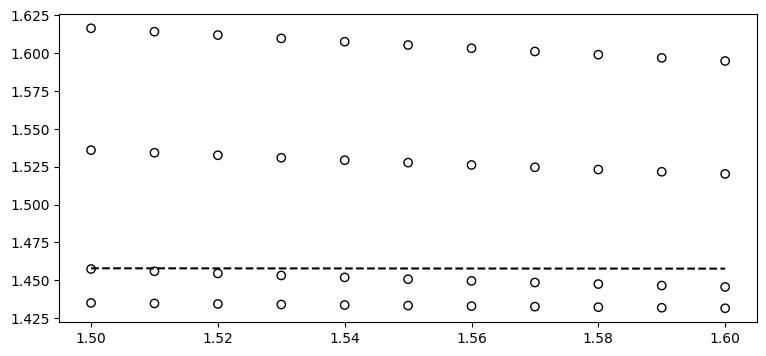

In [264]:
wavelength = np.linspace(1500, 1600, 11) * nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='none',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te_1 = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm_1 = deep_waveguide.fraction_tm # Wavelength-dependent vector

print(res_te_1)
print(res_tm_1)

plt.figure(figsize=(9, 4))
for k in range(4):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(wavelength, box_index,'k--', label='SiO2 index')


Mode 0 and 1 are guided, mode 2 and 3, not. Mode 0 is TE0 and Mode 1 is TM0. Now, we fit the data to the compact model.

,Mode,n_eff(1550 nm),n_g,D (s/m²)
0,TE0,1.605392,1.940433,-0.000995
1,TM0,1.527682,1.771351,-0.001577


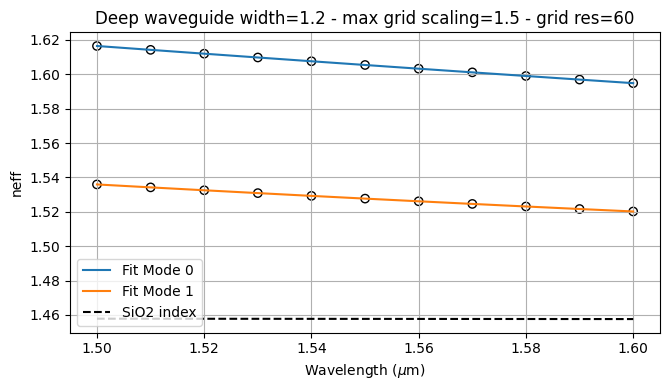

In [267]:
wavelength = np.linspace(1500, 1600, 11) * nm
shift = wavelength - 1550*nm # shift para hacer el ajuste
n_1550 = []
ng = []
Disp = []

# fitteamos solo los modos fundamentales, los dos primeros de "range(res_neff.shape[1])"

plt.figure(figsize=(8, 4))

for k in range(2):
    coeff, cov = np.polyfit(shift, res_neff[:,k].real, 2, cov=True)
    fit = coeff[2] + coeff[1]*shift + coeff[0]*shift**2
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, fit, label=f'Fit Mode {k}')
    n_1550 = np.append(n_1550, coeff[2])
    ng = np.append(ng, coeff[2]- coeff[1]*1550*nm)
    Disp = np.append(Disp, (-2*1550*nm*coeff[0]/td.C_0)*1e12) # s/m^2

plt.title("Deep waveguide width=1.2 - max grid scaling=1.5 - grid res=60")
plt.xlabel(r"Wavelength ($\mu$m)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='lower left')
plt.tight_layout(rect=[0, 0, 0.85, 1])

k = (['TE0', 'TM0'])
df = pd.DataFrame({
    "Mode": k,
    "n_eff(1550 nm)": n_1550,
    "n_g": ng,
    "D (s/m²)": Disp
})
df

### L03.2 Shallow waveguide compact model

A shallow waveguide will have a lot of modes, so we have to look for the TE0 and TM0 modes "manualy". 

We first look for the number of guided modes. Taking 1550 nm, we plot n_eff vs mode number and see if it's greater than n($SiO_2$).

Then, we are gonna implement a loop and calculate for each guided mode, given a certain wavelength, the te and tm fractions.

And finally, we'll do the fit for the TE0 and TM0.

2026-11-09 09:04:46.179 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_75e743a6690b4ad6.npz.


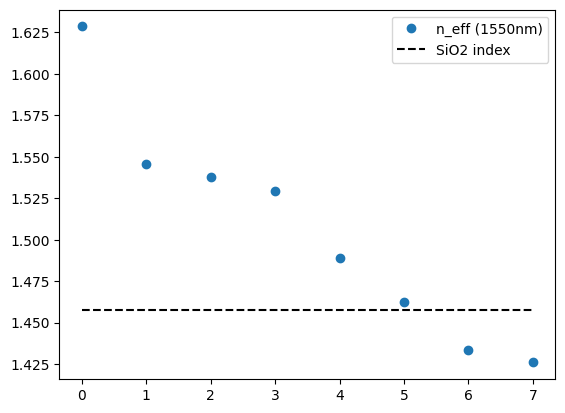

In [12]:
shallow_waveguide = gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=150 * nm,
    num_modes=8,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60, 
)
n_eff = shallow_waveguide.n_eff
plt.plot(np.arange(0,8), n_eff.real, 'o', label='n_eff (1550nm)')
plt.hlines(box_index[5], 0, 7,'k', '--', label='SiO2 index') # box_index[5] es box_index[1550 nm]
plt.legend()

Just the first 6 modes are guided. Although, we must make sure the "guidance" of the modes through all the wavelength interval.

Now, we look for the te and tm fractions.

2026-11-09 20:00:22.911 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_adec95d885b75f8a.npz.
2026-11-09 20:00:22.974 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_46ad8240d85f7b5b.npz.
2026-11-09 20:00:23.020 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_88ab04c9f531bd72.npz.
2026-11-09 20:00:23.046 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c44307c2f034bfcd.npz.
2026-11-09 20:00:23.075 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9d534a2dfee79c26.npz.
2026-11-09 20:00:23.115 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ce3b95e082742f69.npz.
2026-11-09 20:00:23.144 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_535724050a1e8d90.npz.
2026-11-09 20:00:23.176 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_bcb8deeafed23de9.npz.


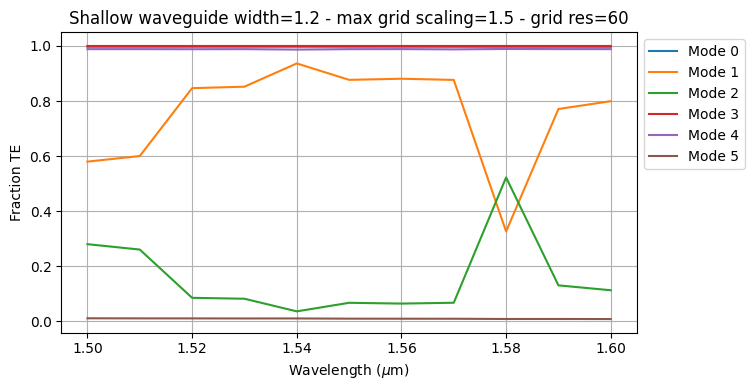

In [223]:
wavelength = np.linspace(1500, 1600, 11) * nm

res_neff = np.zeros((len(wavelength),6), dtype=complex)
res_te = np.zeros((len(wavelength),6))
res_tm = np.zeros((len(wavelength),6))

for k in range(wavelength.shape[0]): # for each wavelength, find 6 guided modes and its n_eff, te and tm fractions
    shallow_waveguide = gt.modes.Waveguide(
        wavelength=(1500+k*10)*nm,
        core_width=1.2,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        slab_thickness=150 * nm,
        num_modes=6,
        precision='double',
        cache_path='.cache/',
        max_grid_scaling=1.5,
        grid_resolution=60, 
    )

    res_neff[k,:]=shallow_waveguide.n_eff
    res_te[k,:]=shallow_waveguide.fraction_te
    res_tm[k,:]=shallow_waveguide.fraction_tm


# res_neff = np.array(res_neff)
# res_te = np.array(res_te)
# res_tm = np.array(res_tm)

plt.figure(figsize=(9, 4))
for k in range(res_neff.shape[1]): # k is the number of modes
    plt.plot(wavelength, res_te[:,k],label = f'Mode {k}')

plt.title("Shallow waveguide width=1.2 - max grid scaling=1.5 - grid res=60")
plt.xlabel(r"Wavelength ($\mu$m)")
plt.ylabel("Fraction TE")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
print(res_te)

Indeed, the 6 modes are guided for 1.5 - 1.6 $\mu m$. Looking at the te_fraction, Mode 0 is TE0 and Mode 5 is TM0.

ESTOY ENFRENTANDO UN PROBLEMA CON EL ÍNDICE EFECTIVO. NO ENTIENDO POR QUÉ, PERO NO DA LO MISMO USANDO EL BUCLE ANTERIOR QUE LLAMANDO A LA FUNCIÓN CON UN VECTOR DE LONGITUDES DE ONDA, QUE ES COMO LO REALIZAMOS FINALMENTE.

Finally, we can do the fit of the compact model for the two modes.

2026-11-09 20:00:27.381 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_1918aa2a075e02f3.npz.


,Mode,n_eff(1550 nm),n_g,D (s/m²)
0,TE0,1.624628,1.916085,-0.000983
1,TM0,1.463179,1.646889,-0.000892


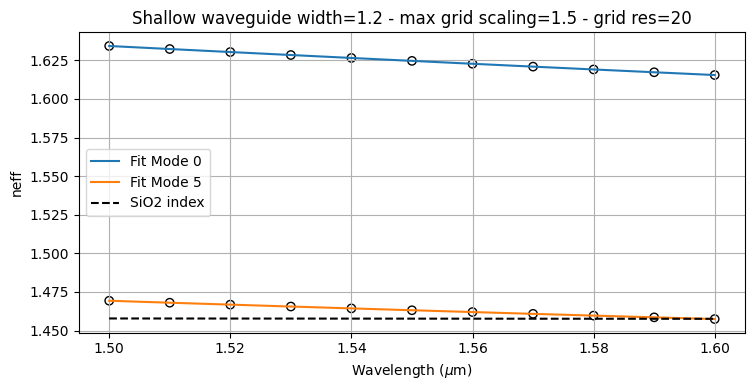

In [224]:
wavelength = np.linspace(1500, 1600,11) * nm

n_1550 = []
ng = []
Disp = []

shallow_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=150 * nm,
    num_modes=6,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60 
)

res_neff = shallow_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = shallow_waveguide.fraction_te # Wavelength-dependent vector
res_tm = shallow_waveguide.fraction_tm # Wavelength-dependent vector

# fitteamos solo los modos fundamentales
modes = ([0,5])

shift = wavelength - 1550*nm

plt.figure(figsize=(9, 4))
for m in modes:
    coeff, cov = np.polyfit(shift, res_neff[:,m].real, 2, cov=True)
    fit = coeff[2] + coeff[1]*shift + coeff[0]*shift**2
    plt.scatter(wavelength, res_neff[:,m].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, fit, label=f'Fit Mode {m}')
    n_1550.append(coeff[2])
    ng.append(coeff[2]- coeff[1]*1550*nm)
    Disp.append((-2*1550*nm*coeff[0]/td.C_0)*1e12) # s/m^2

plt.title("Shallow waveguide width=1.2 - max grid scaling=1.5 - grid res=20")
plt.xlabel(r"Wavelength ($\mu$m)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='center left')
plt.tight_layout(rect=[0, 0, 0.85, 1])

k = (['TE0', 'TM0'])
df = pd.DataFrame({
    "Mode": k,
    "n_eff(1550 nm)": n_1550,
    "n_g": ng,
    "D (s/m²)": Disp
})
df

## LO.4. Bend waveguide radius vs. loss – deep

The bend loss has three primary contributions:

1. Mode-mismatch loss
2. Radiation loss
3. Propagation loss

Deep waveguide - width 1.0 $\mu m$ - 1550 nm

How many modes does this straight waveguide have?

2026-11-09 17:44:22.251 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_dec22bc90f39d9e5.npz.
[0.99461869 0.0092728  0.89769095 0.09807689]


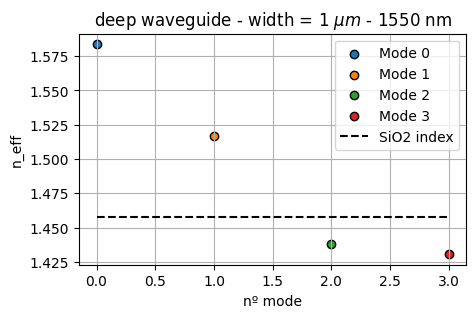

In [110]:
single = gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=1.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60,
)

n_eff = single.n_eff
print(single.fraction_te)

plt.figure(figsize=(5,3))
for k in range(4):
    plt.scatter(k, n_eff[k].real,edgecolors='k', label=f'Mode {k}')
plt.hlines(box_index[5], 0, 3,'k', '--', label='SiO2 index') # box_index[5] es box_index[1550 nm]

plt.title(r'deep waveguide - width = 1 $\mu m$ - 1550 nm')
plt.ylabel('n_eff')
plt.xlabel('nº mode')
plt.grid()
plt.legend()

In this waveguide, when it's not bended, for 1550 nm, there are only 2 guided modes.

### Mode-mismatch loss

Bend waveguide mode differs slightly from the straight waveguide mode, wich yield into mode-convertion losses. We can calculate this factor as the overlap of the latter two modes. 

This is already implemented on GDSfactory library: 

We are gonna evaluate the mismatch loss for radii (25, 50, 75, 100, 125, 150) $\mu m$. Also, we are going to calculate the n_eff, and the fraction te and tm of the modes, because we need to discern which are the TE0 and TM0 modes.

In [111]:
%%capture
bend_waveguide = gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=1.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=2,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60,
    bend_radius=50,
)

radii = np.array([25, 50, 75, 100, 125, 150]) #um

sweep_neff = gt.modes.sweep_n_eff(bend_waveguide, 
                             bend_radius=radii)

sweep_tefraction = gt.modes.sweep_fraction_te(bend_waveguide,
                                              bend_radius=radii)


2026-11-09 17:53:17.424 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_65d553bd659fbd78.npz.
2026-11-09 17:53:42.319 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_94f9deb65b518dfc.npz.
2026-11-09 17:54:04.928 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_d7c979151f9fc414.npz.
2026-11-09 17:54:31.986 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_824e7f8b8ad5d620.npz.
2026-11-09 17:54:53.535 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_a2950b81810888f8.npz.
2026-11-09 17:55:17.460 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_0a372807c5bf9eef.npz.
2026-11-09 17:55:17.599 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_65d553bd659fbd78.npz.
2026-11-09 17:55:17.767 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_94f9deb65b518dfc

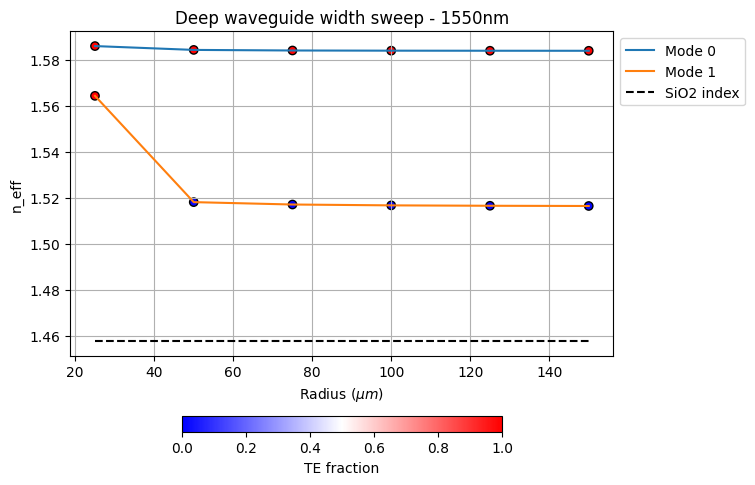

In [113]:
plt.figure(figsize=(9, 5))
for k in range(sweep_neff.shape[1]): # k es el nº del mode
    plt.scatter(radii, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(radii, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel(r"Radius ($\mu m$)")
plt.ylabel("n_eff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(radii), xmax=np.max(radii), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")


There are some tricky problems with the solver, because Mode 1 is switching polarizations. We can look for more modes to see what's happening.

In [166]:
%%capture
bend_waveguide = gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=1.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60,
    bend_radius=50,
)

radii = np.array([25, 50, 75, 100, 125, 150]) #um

sweep_neff = gt.modes.sweep_n_eff(bend_waveguide, 
                             bend_radius=radii)

sweep_tefraction = gt.modes.sweep_fraction_te(bend_waveguide,
                                              bend_radius=radii)

2026-11-09 18:39:41.471 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d2a6f781535e0b18.npz.
2026-11-09 18:39:41.531 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a31dc1a8efc04c96.npz.
2026-11-09 18:39:41.541 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a46db2e574ad222f.npz.
2026-11-09 18:39:41.549 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_54f8a2fe8c37df5e.npz.
2026-11-09 18:39:41.556 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_8153b32f4d9016d5.npz.
2026-11-09 18:39:41.567 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_56756def17363c89.npz.
2026-11-09 18:39:41.601 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d2a6f781535e0b18.npz.
2026-11-09 18:39:41.614 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a31dc1a8efc04c96.npz.


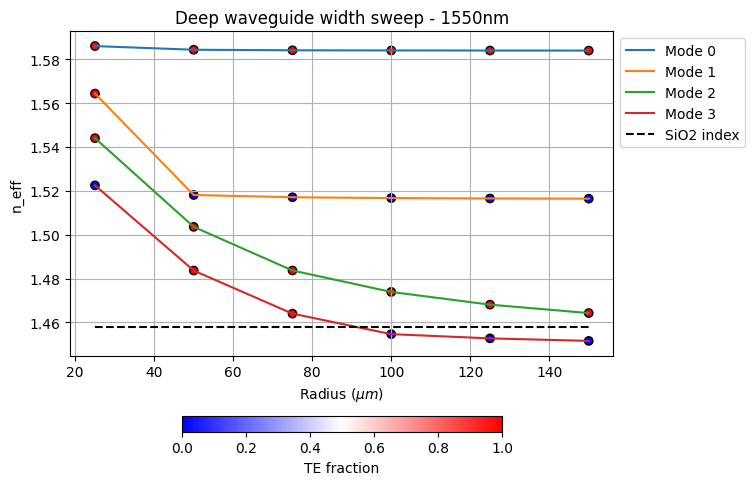

In [167]:
plt.figure(figsize=(9, 5))
for k in range(sweep_neff.shape[1]): # k es el nº del mode
    plt.scatter(radii, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(radii, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel(r"Radius ($\mu m$)")
plt.ylabel("n_eff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(radii), xmax=np.max(radii), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

The software it's "changing" the order of the modes at R = 25 $\mu m$, but we can clearly see that the mode 0 is the TE0 for every radii, and the mode 1 is the TM0 for radii R > 25, but mode 3 for R = 25.

Also, we have seen that the straight version of the waveguide at 1550 nm only supports two modes, so the additional two modes that we see here, despite having $n_{eff} > n_{SiO_2}$ are probably LEAKY modes or something. Moreover, if we look at the imaginary part of n_eff, we probably see that its greater for these two additional modes.

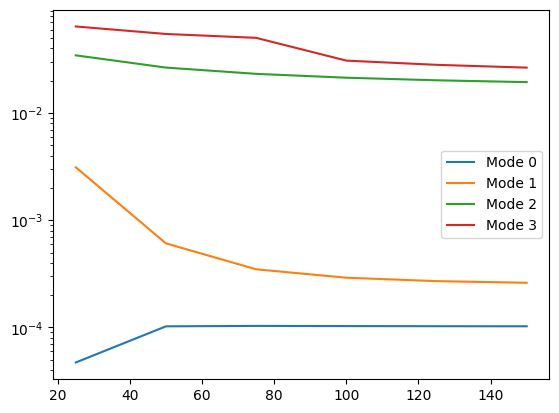

In [ ]:
n_0 = sweep_neff[:,0]
# we exchange the first data point of the modes to its corresponent order
n_1 = [sweep_neff[0,3],sweep_neff[1,1],sweep_neff[2,1],sweep_neff[3,1],sweep_neff[4,1],sweep_neff[5,1]]
n_2 = [sweep_neff[0,1],sweep_neff[1,2],sweep_neff[2,2],sweep_neff[3,2],sweep_neff[4,2],sweep_neff[5,2]]
n_3 = [sweep_neff[0,2],sweep_neff[1,3],sweep_neff[2,3],sweep_neff[3,3],sweep_neff[4,3],sweep_neff[5,3]]
# para estos tres hay que permutar el primer dato 
plt.semilogy(radii, np.abs(np.imag(n_0)), label='Mode 0')
plt.semilogy(radii, np.abs(np.imag(n_1)), label='Mode 1')
plt.semilogy(radii, np.abs(np.imag(n_2)), label='Mode 2')
plt.semilogy(radii, np.abs(np.imag(n_3)), label='Mode 3')
plt.legend()


The imaginary part of the modes 2 and 3 are too high for a guided mode. We can also visualize the cross field of these 4 modes at the problematic point R = 25 $\mu m$ to verify this theory.

2026-11-09 18:47:14.878 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d2a6f781535e0b18.npz.


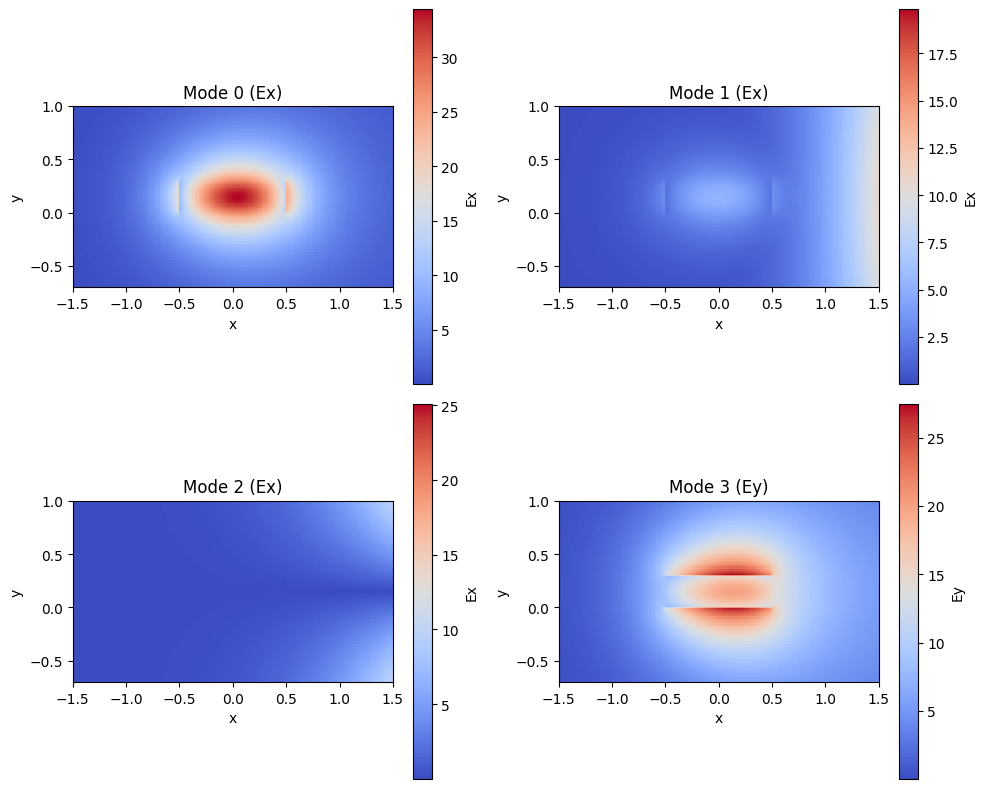

In [171]:
bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=1.0,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60, 
    bend_radius=25, # Bend radius
)

# prove = bend_1550.n_eff
# fr_te = bend_1550.fraction_te
# print(prove)
# print(fr_te)
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

bend_1550.plot_field(
    field_name="Ex",
    mode_index=0,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[0,0],
)
axs[0,0].set_title("Mode 0 (Ex)")

bend_1550.plot_field(
    field_name="Ex",
    mode_index=1,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[0,1],
)
axs[0,1].set_title("Mode 1 (Ex)")

bend_1550.plot_field(
    field_name="Ex",
    mode_index=2,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[1,0],
)
axs[1,0].set_title("Mode 2 (Ex)")

bend_1550.plot_field( # these mode is TM (previous figure)
    field_name="Ey",
    mode_index=3,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[1,1],
)
axs[1,1].set_title("Mode 3 (Ey)")

plt.tight_layout()
plt.show()

We can conclude, then, that there are only two guided modes, TE0 (mode 0) and TM0 (mode 1/mode 3), and that the software is finding additional converging modes. Thus, for the next part, we'll take this into account.

In [178]:
%%capture

bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=1.0,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60, 
    bend_radius=50, # Bend radius
)

radii = np.array([25, 50, 75, 100, 125, 150]) #um
mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)

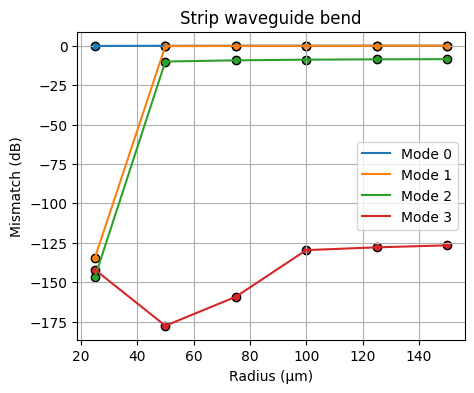

In [179]:
plt.figure(figsize=(5,4))
for k in range(mismatch.shape[1]): # k es el nº del mode
    plt.scatter(radii, 10 * np.log10(mismatch[:,k]),edgecolors='k')
    plt.plot(radii, 10 * np.log10(mismatch[:,k]),label=f'Mode {k}')
# plt.plot(radii, 10 * np.log10(mismatch_TE0), 'bo-', label='Mode TE0')
# plt.plot(radii, 10 * np.log10(mismatch_TM0), 'rs-', label='Mode TM0')
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.grid()
plt.legend()

Although we know there has to be a guided TM0, the losses for the modes except the TE0 (mode 0) are too high for R = 25 $\mu m$. There doesn't seem to be any tricky exchange of values between modes due to the software. This may be telling us that:

- or TM0 losses are, in fact, that high,
- or the solver isn't able to find the "correct" value.

Anyways, for consistency, we are going to assume there is an exchange of values between the three last modes at R = 25, as it has happened before.

In [180]:
mismatch_TE0 = mismatch[:,0]
mismatch_TM0 = mismatch[:,1]
print(mismatch_TM0)
mismatch_TM0[0] = mismatch[0,3]
print(mismatch_TM0)

[3.43722105e-14 9.44007229e-01 9.72935773e-01 9.81976190e-01
 9.85898427e-01 9.87948781e-01]
[6.20876232e-15 9.44007229e-01 9.72935773e-01 9.81976190e-01
 9.85898427e-01 9.87948781e-01]


### Propagation loss

Consider the equivalent linear length of the quarter-circle bend. Light will attenuate following a trend quantified with the experimentally measured parameter $$\alpha [\mathrm{dB}/\mathrm{cm}]$$. It depends on the fabrication process mainly. We will add this loss (in dBs) to the mode-mismatch loss to calculate the total loss per bend. 

*We are not considering the radiation losses, mainly because is not easy to implement a quick simulation for this parameter. Under certain conditions, the main loss sources are the ones considered in this example


(0.0, 0.4)

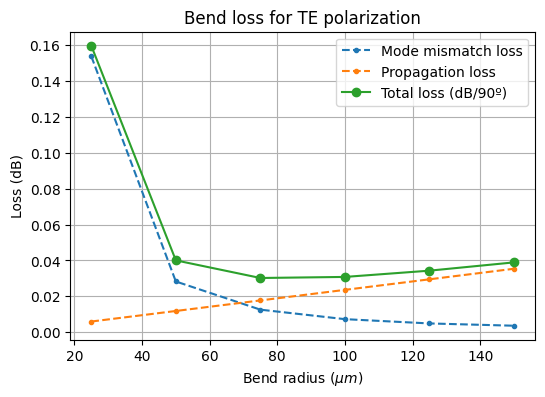

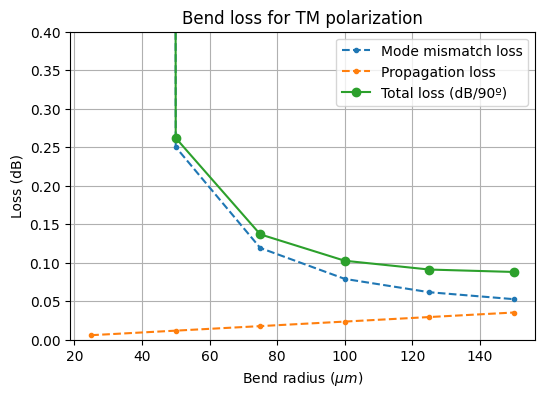

In [182]:
dB_cm = 1.5  # dB/cm Technology loss
length = 0.5 * np.pi * radii * 1e-6 # m
propagation_loss = dB_cm * length * 1e2 # m

plt.figure(figsize=(6,4))
plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch_TE0), ".--", label="Mode mismatch loss")
plt.plot(radii, propagation_loss, ".--", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_TE0), "o-", label="Total loss (dB/90º)")
plt.xlabel(r"Bend radius ($\mu m$)")
plt.ylabel("Loss (dB)")
plt.grid()
plt.legend()

plt.figure(figsize=(6,4))
plt.title("Bend loss for TM polarization")
plt.plot(radii, -10 * np.log10(mismatch_TM0), ".--", label="Mode mismatch loss")
plt.plot(radii, propagation_loss, ".--", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_TM0), "o-", label="Total loss (dB/90º)")
plt.xlabel(r"Bend radius ($\mu m$)")
plt.ylabel("Loss (dB)")
plt.grid()
plt.legend()
plt.ylim(0,0.40)

## EXTRA

All the past simulations were done considering as core material de Silicon Nitride (SiNx) and Silicon Dioxide (SiO2) as cladding material. Now, **simulate the Silicon-On-Insulator technology changing the core material to Silicon (Si)**. In this case, the dimensions will be 220 nm heigth and 500 nm width. 
1. Repeat the LO.1. wavelength behavior simulations, considering the updated materials and dimensions. 
2. Repeat the LO.3. width dependence analysis, now sweeping in a 300nm - 1um range. 
3. Find the safe radius for this technology. Consider sweeping the radius in a 5um to 30um range. 
4. **Compare the SiNx and SOI technologies** 

### Convergence tests

In [201]:
%%capture

g_res_1 = np.linspace(10, 100, 10) #steps of 10
g_res_2 = np.linspace(10, 100, 19) #steps of 5

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=500*nm, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

# el sweep de n_eff podem fer-lo per al mode fonamental només
sweep_neff_1 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  grid_resolution=g_res_1)

sweep_neff_2 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  grid_resolution=g_res_2)

2026-11-09 19:39:23.054 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4a1d722b79a898fe.npz.
2026-11-09 19:39:23.066 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_03f4f47742c6dd39.npz.
2026-11-09 19:39:23.080 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_df6b8c7ded5c819f.npz.
2026-11-09 19:39:23.090 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e180c41701f0a45c.npz.
2026-11-09 19:39:23.104 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_99c2a1f132c5aa29.npz.
2026-11-09 19:39:23.113 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_376ad1e6757d68e9.npz.
2026-11-09 19:39:23.123 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d39692b947d95237.npz.
2026-11-09 19:39:23.132 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_778e926092e76bcf.npz.


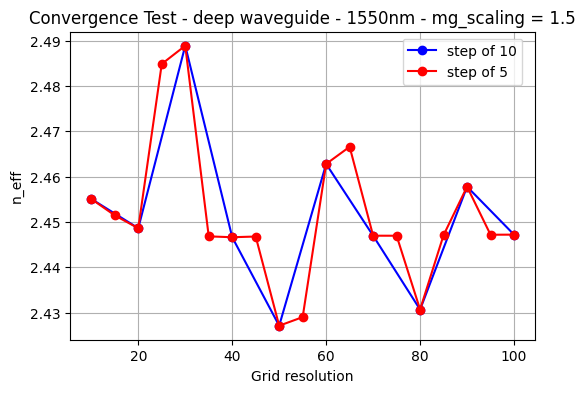

In [202]:
plt.figure(figsize=(6, 4))
plt.plot(g_res_1,sweep_neff_1.real,'bo-',label='step of 10')
plt.plot(g_res_2,sweep_neff_2.real,'ro-',label='step of 5')
plt.title("Convergence Test - deep waveguide - 1550nm - mg_scaling = 1.5")
plt.xlabel("Grid resolution")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(0.7,1))

In [271]:
%%capture
mg_scaling_1 = np.linspace(1.2, 1.6, 5) # pasos de 0.1
mg_scaling_2 = np.linspace(1.2, 1.6, 9) # pasos de 0.05

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=500*nm, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

# el sweep de n_eff podem fer-lo per al mode fonamental només
sweep_neff_1 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_1)

sweep_neff_2 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_2)

2026-11-09 21:30:07.694 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cc4fc10128af5cd3.npz.
2026-11-09 21:30:07.797 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0dde524baa930045.npz.
2026-11-09 21:30:07.822 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_f1e069993e9b7864.npz.
2026-11-09 21:30:07.854 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_03f4f47742c6dd39.npz.
2026-11-09 21:30:07.880 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e6ce3eac15aa54b7.npz.
2026-11-09 21:30:07.939 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cc4fc10128af5cd3.npz.
2026-11-09 21:30:07.946 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_359dfc2df548b08f.npz.
2026-11-09 21:30:07.972 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0dde524baa930045.npz.


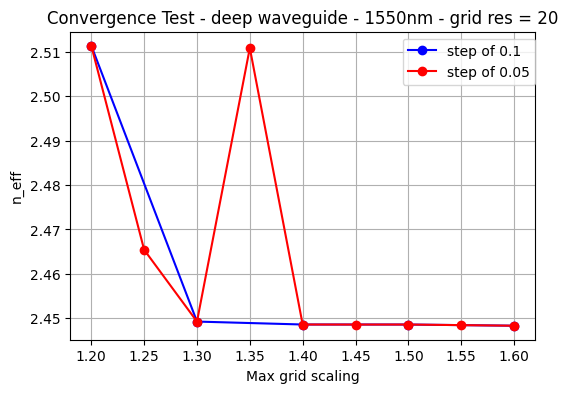

In [272]:
plt.figure(figsize=(6, 4))
plt.plot(mg_scaling_1,sweep_neff_1.real,'bo-',label='step of 0.1')
plt.plot(mg_scaling_2,sweep_neff_2.real,'ro-',label='step of 0.05')
plt.title("Convergence Test - deep waveguide - 1550nm - grid res = 20")
plt.xlabel("Max grid scaling")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(0.7,1))

We are going to proceed for the next steps with a grid_res = 20 because it's part of the stable value tendency of n_eff. If a problem shows up, we will upgrade the grid resolution up to 70, where n_eff value is similar, but allows the software to work more precisely. 

In [268]:
%%capture
mg_scaling_1 = np.linspace(1.2, 1.6, 5) # pasos de 0.1
mg_scaling_2 = np.linspace(1.2, 1.6, 9) # pasos de 0.05

deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=500*nm, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=70, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

# el sweep de n_eff podem fer-lo per al mode fonamental només
sweep_neff_1 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_1)

sweep_neff_2 = gt.modes.sweep_n_eff(deep_waveguide, 
                                  max_grid_scaling=mg_scaling_2)

2026-11-09 21:01:28.484 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_e49bc813c842a7c0.npz.
2026-11-09 21:01:54.964 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_5456e38249d9e669.npz.
2026-11-09 21:02:15.802 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_c468cfe0b6213477.npz.
2026-11-09 21:02:15.836 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d39692b947d95237.npz.
2026-11-09 21:02:34.242 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_54b49ed0042796b3.npz.
2026-11-09 21:02:34.331 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e49bc813c842a7c0.npz.
2026-11-09 21:02:59.911 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_035c9760f5d05443.npz.
2026-11-09 21:02:59.958 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5456e38249d9e669.

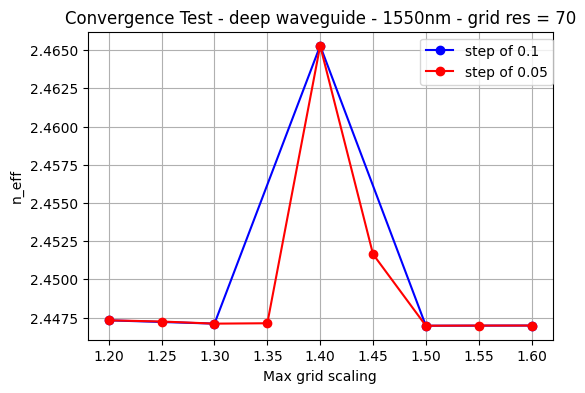

In [270]:
plt.figure(figsize=(6, 4))
plt.plot(mg_scaling_1,sweep_neff_1.real,'bo-',label='step of 0.1')
plt.plot(mg_scaling_2,sweep_neff_2.real,'ro-',label='step of 0.05')
plt.title("Convergence Test - deep waveguide - 1550nm - grid res = 70")
plt.xlabel("Max grid scaling")
plt.ylabel("n_eff")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(0.7,1))

### Width dependance

  0%|          | 0/8 [00:00<?, ?it/s]

2026-11-09 19:41:05.391 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c1c872f7074fee70.npz.
2026-11-09 19:41:05.401 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_25ac43ce498009e4.npz.
2026-11-09 19:41:05.411 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9b607c2ee0ef414d.npz.
2026-11-09 19:41:05.415 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c4d234335cc9cbca.npz.
2026-11-09 19:41:05.425 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a0fa77afa602dc4d.npz.
2026-11-09 19:41:05.429 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ff2aab0f5bee5c27.npz.
2026-11-09 19:41:05.437 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_72ba7480dd04b379.npz.
2026-11-09 19:41:05.443 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd251c5aeb871026.npz.


  0%|          | 0/8 [00:00<?, ?it/s]

2026-11-09 19:41:05.465 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c1c872f7074fee70.npz.
2026-11-09 19:41:05.475 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_25ac43ce498009e4.npz.
2026-11-09 19:41:05.482 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9b607c2ee0ef414d.npz.
2026-11-09 19:41:05.488 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c4d234335cc9cbca.npz.
2026-11-09 19:41:05.493 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a0fa77afa602dc4d.npz.
2026-11-09 19:41:05.497 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ff2aab0f5bee5c27.npz.
2026-11-09 19:41:05.503 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_72ba7480dd04b379.npz.
2026-11-09 19:41:05.510 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_fd251c5aeb871026.npz.


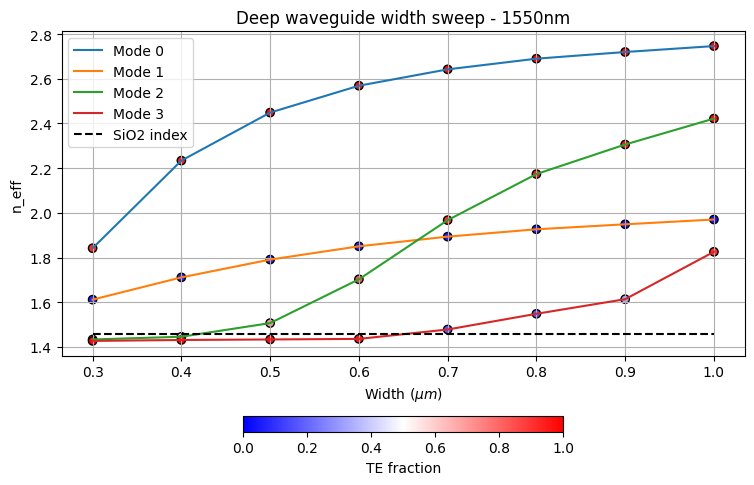

In [205]:
wavelength = 1550*nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=500*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20, 
)

w = np.linspace(0.3, 1., 8) # pasos de 0.1

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

# we have seen that there is a "mode crossing"
n_0 = sweep_neff[:,0].real
n_1 = [sweep_neff[0,1].real,sweep_neff[1,1].real,sweep_neff[2,1].real,sweep_neff[3,1].real,
       sweep_neff[4,2].real,sweep_neff[5,2].real,sweep_neff[6,2].real,sweep_neff[7,2].real]
n_2 = [sweep_neff[0,2].real,sweep_neff[1,2].real,sweep_neff[2,2].real,sweep_neff[3,2].real,
       sweep_neff[4,1].real,sweep_neff[5,1].real,sweep_neff[6,1].real,sweep_neff[7,1].real]
n_3 = sweep_neff[:,3].real

plt.figure(figsize=(9, 5))
for k in range(sweep_neff.shape[1]): # k es el nº del mode
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    
plt.plot(w, n_0,label=f'Mode {0}')
plt.plot(w, n_1,label=f'Mode {1}')
plt.plot(w, n_2,label=f'Mode {2}')
plt.plot(w, n_3,label=f'Mode {3}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel(r"Width ($\mu m$)")
plt.ylabel("n_eff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(0, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

### Compact model

#### deep waveguide

2026-11-09 22:06:28.985 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from none\Waveguide_77d79a6896198cce.npz.
[0.97534483 0.06716702 0.70509956 0.99470673]
[0.02465517 0.93283298 0.29490044 0.00529327]


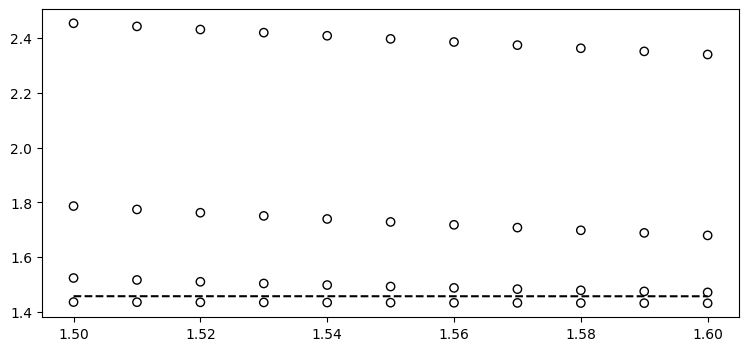

In [277]:
wavelength = np.linspace(1500, 1600, 11) * nm

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=500*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='none',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te_1 = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm_1 = deep_waveguide.fraction_tm # Wavelength-dependent vector

print(res_te_1)
print(res_tm_1)

plt.figure(figsize=(9, 4))
for k in range(4):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(wavelength, box_index,'k--', label='SiO2 index')


Looking at the polarization fractions, mode 0 is TE0 and mode 1 is TM0. Then we apply the model to these two modes.

,Mode,n_eff(1550 nm),n_g,D (s/m²)
0,TE0,2.396304,4.161666,0.000017
1,TM0,1.728700,3.385764,-0.018285


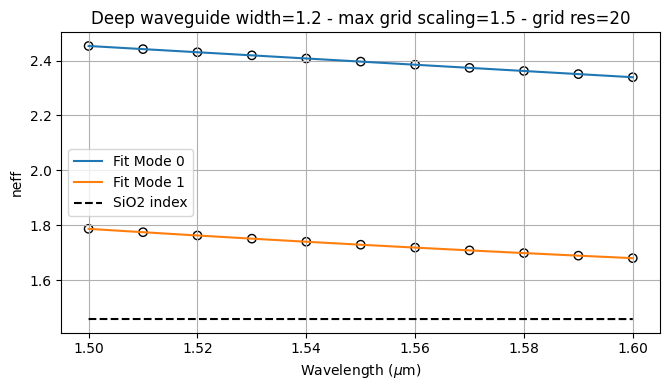

In [278]:
wavelength = np.linspace(1500, 1600, 11) * nm
shift = wavelength - 1550*nm # shift para hacer el ajuste
n_1550 = []
ng = []
Disp = []

# fitteamos solo los modos fundamentales, los dos primeros de "range(res_neff.shape[1])"

plt.figure(figsize=(8, 4))

for k in range(2):
    coeff, cov = np.polyfit(shift, res_neff[:,k].real, 2, cov=True)
    fit = coeff[2] + coeff[1]*shift + coeff[0]*shift**2
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, fit, label=f'Fit Mode {k}')
    n_1550 = np.append(n_1550, coeff[2])
    ng = np.append(ng, coeff[2]- coeff[1]*1550*nm)
    Disp = np.append(Disp, (-2*1550*nm*coeff[0]/td.C_0)*1e12) # s/m^2

plt.title("Deep waveguide width=1.2 - max grid scaling=1.5 - grid res=20")
plt.xlabel(r"Wavelength ($\mu$m)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='center left')
plt.tight_layout(rect=[0, 0, 0.85, 1])

k = (['TE0', 'TM0'])
df = pd.DataFrame({
    "Mode": k,
    "n_eff(1550 nm)": n_1550,
    "n_g": ng,
    "D (s/m²)": Disp
})
df

#### Shallow waveguide

2026-11-09 22:06:49.003 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_26ab0445ab8342d6.npz.


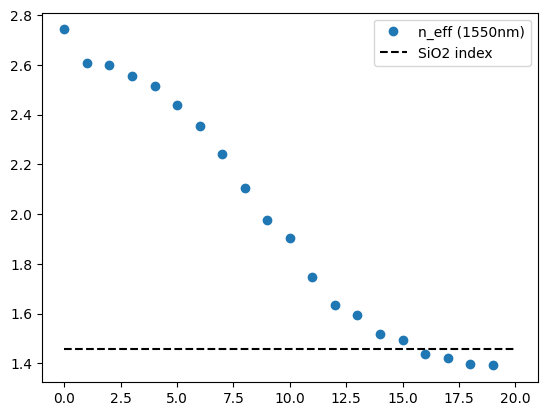

In [279]:
shallow_waveguide = gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=500*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=150 * nm,
    num_modes=20,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20, 
)
n_eff = shallow_waveguide.n_eff
plt.plot(np.arange(0,20), n_eff.real, 'o', label='n_eff (1550nm)')
plt.hlines(box_index[5], 0, 20,'k', '--', label='SiO2 index') # box_index[5] es box_index[1550 nm]
plt.legend()

16 guided modes. Which one is the TE0 and which one the TM0?

In [280]:
wavelength = np.linspace(1500, 1600, 11) * nm

res_neff = np.zeros((len(wavelength),16), dtype=complex)
res_te = np.zeros((len(wavelength),16))
res_tm = np.zeros((len(wavelength),16))

for k in range(wavelength.shape[0]): # for each wavelength, find 6 guided modes and its n_eff, te and tm fractions
    shallow_waveguide = gt.modes.Waveguide(
        wavelength=(1500+k*10)*nm,
        core_width=500*nm,
        core_material='si',
        clad_material='sio2',
        core_thickness=220 * nm,
        slab_thickness=150 * nm,
        num_modes=16,
        precision='double',
        cache_path='.cache/',
        max_grid_scaling=1.5,
        grid_resolution=20, 
    )

    res_neff[k,:]=shallow_waveguide.n_eff
    res_te[k,:]=shallow_waveguide.fraction_te
    res_tm[k,:]=shallow_waveguide.fraction_tm


# res_neff = np.array(res_neff)
# res_te = np.array(res_te)
# res_tm = np.array(res_tm)

# pass on the plot because it'll be messy.

print(res_te)

2026-11-09 22:06:53.133 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7b3385445888070c.npz.
2026-11-09 22:06:53.168 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_caccdf8bb02ccedb.npz.
2026-11-09 22:06:53.196 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_41db7f53e8de5d20.npz.
2026-11-09 22:06:53.221 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_b0efa7c3a04dd92f.npz.
2026-11-09 22:06:53.251 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5cae5e866f12752c.npz.
2026-11-09 22:06:53.272 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2641e5dfdfcfffb2.npz.
2026-11-09 22:06:53.299 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c5120c1d3416247e.npz.
2026-11-09 22:06:53.321 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_34b6173c4e3c4204.npz.


Mode 0 = Te0, Mode 13 = TM0

2026-11-09 22:06:58.199 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9685e7da75706e3f.npz.


,Mode,n_eff(1550 nm),n_g,D (s/m²)
0,TE0,2.635852,3.723894,-0.002061
1,TM0,1.548706,2.310383,-0.003884


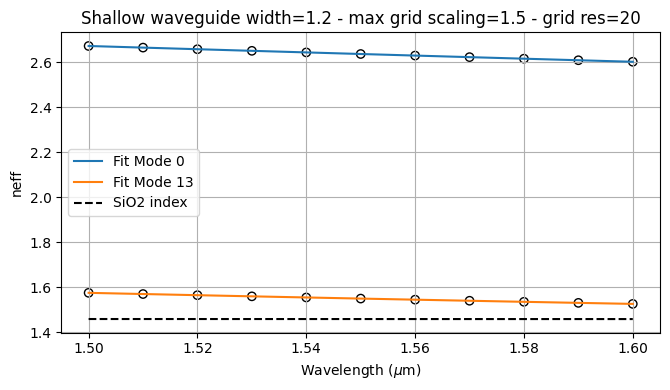

In [281]:
wavelength = np.linspace(1500, 1600,11) * nm

n_1550 = []
ng = []
Disp = []

shallow_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=500*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=150 * nm,
    num_modes=16,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20 
)

res_neff = shallow_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = shallow_waveguide.fraction_te # Wavelength-dependent vector
res_tm = shallow_waveguide.fraction_tm # Wavelength-dependent vector

# fitteamos solo los modos fundamentales
modes = ([0,13])

shift = wavelength - 1550*nm

plt.figure(figsize=(8, 4))
for m in modes:
    coeff, cov = np.polyfit(shift, res_neff[:,m].real, 2, cov=True)
    fit = coeff[2] + coeff[1]*shift + coeff[0]*shift**2
    plt.scatter(wavelength, res_neff[:,m].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, fit, label=f'Fit Mode {m}')
    n_1550.append(coeff[2])
    ng.append(coeff[2]- coeff[1]*1550*nm)
    Disp.append((-2*1550*nm*coeff[0]/td.C_0)*1e12) # s/m^2

plt.title("Shallow waveguide width=1.2 - max grid scaling=1.5 - grid res=20")
plt.xlabel(r"Wavelength ($\mu$m)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='center left')
plt.tight_layout(rect=[0, 0, 0.85, 1])

k = (['TE0', 'TM0'])
df = pd.DataFrame({
    "Mode": k,
    "n_eff(1550 nm)": n_1550,
    "n_g": ng,
    "D (s/m²)": Disp
})
df

### Bending situation

2026-11-09 22:08:51.359 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9b607c2ee0ef414d.npz.
[0.97579525 0.06630413 0.71276936 0.99259802]


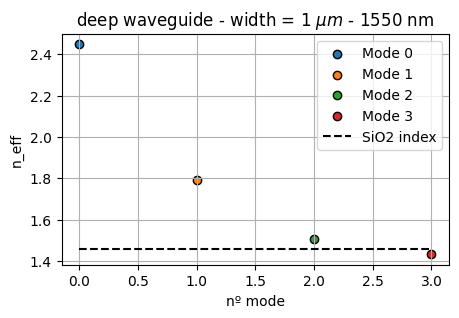

In [282]:
single = gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=500*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20,
)

n_eff = single.n_eff
print(single.fraction_te)

plt.figure(figsize=(5,3))
for k in range(4):
    plt.scatter(k, n_eff[k].real,edgecolors='k', label=f'Mode {k}')
plt.hlines(box_index[5], 0, 3,'k', '--', label='SiO2 index') # box_index[5] es box_index[1550 nm]

plt.title(r'deep waveguide - width = 1 $\mu m$ - 1550 nm')
plt.ylabel('n_eff')
plt.xlabel('nº mode')
plt.grid()
plt.legend()

Mode 0 = TE0, Mode 1 = TM0

#### Mismatch loss - Si

In [287]:
%%capture
bend_waveguide = gt.modes.Waveguide(
    wavelength=1550*nm,
    core_width=500*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20,
    bend_radius=50,
)

radii = np.linspace(5.0, 30, 6)

sweep_neff = gt.modes.sweep_n_eff(bend_waveguide, 
                             bend_radius=radii)

sweep_tefraction = gt.modes.sweep_fraction_te(bend_waveguide,
                                              bend_radius=radii)


2026-11-09 22:56:17.570 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d261128bba3c23c7.npz.
2026-11-09 22:56:17.677 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ab0be676b06903e7.npz.
2026-11-09 22:56:17.705 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ec3dc83a9397180a.npz.
2026-11-09 22:56:17.712 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_17beac6ec49ea465.npz.
2026-11-09 22:56:17.722 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7145740d6f5044ce.npz.
2026-11-09 22:56:17.734 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c8d3c2daaed3503a.npz.
2026-11-09 22:56:17.886 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d261128bba3c23c7.npz.
2026-11-09 22:56:17.901 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ab0be676b06903e7.npz.


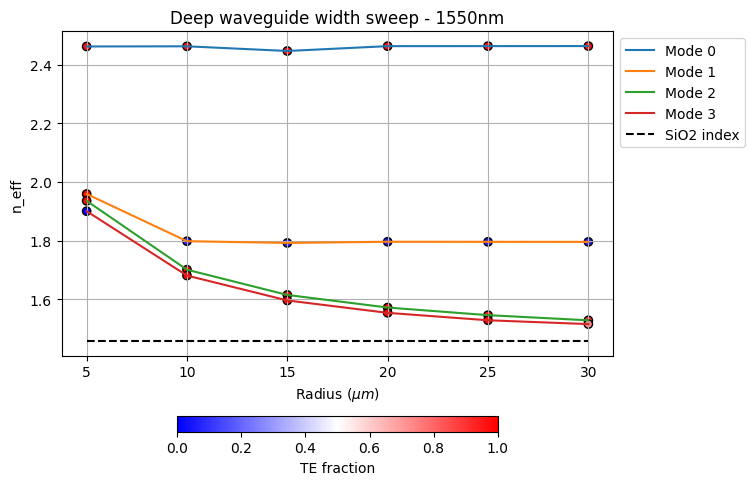

In [288]:
plt.figure(figsize=(9, 5))
for k in range(sweep_neff.shape[1]): # k es el nº del mode
    plt.scatter(radii, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(radii, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel(r"Radius ($\mu m$)")
plt.ylabel("n_eff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(radii), xmax=np.max(radii), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

Here, there is also a mode exchange by the solver. Let's visualize the modes.

2026-11-09 22:09:32.002 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d261128bba3c23c7.npz.


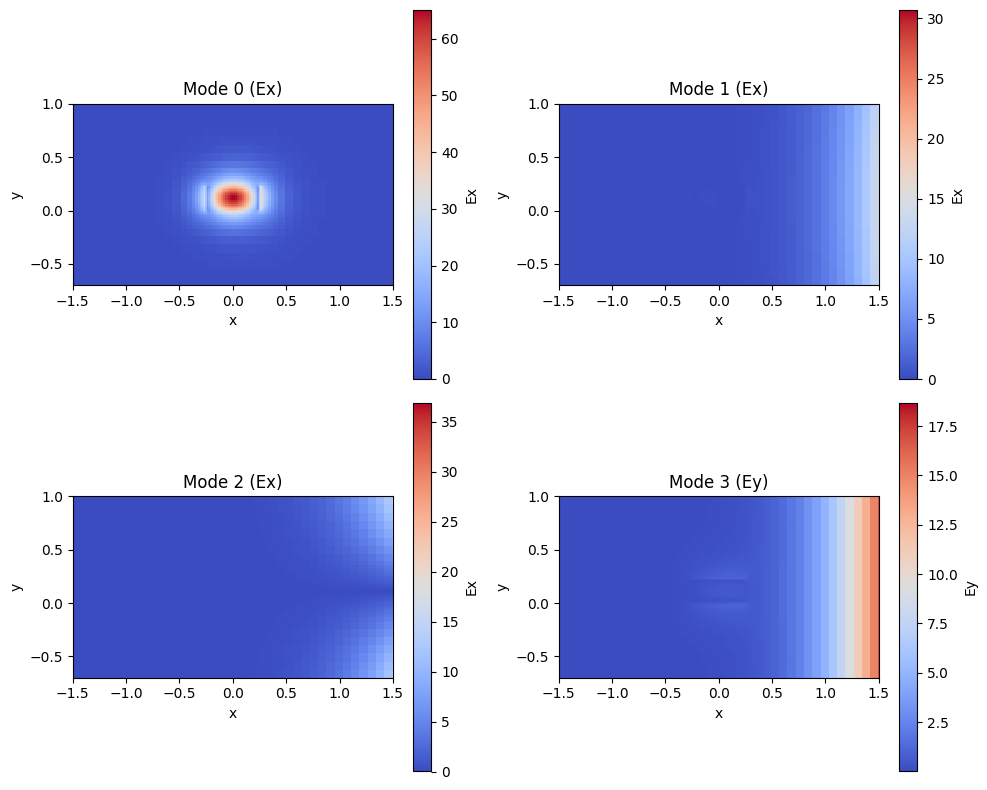

In [285]:
bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=500*nm,
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20, 
    bend_radius=5, # Bend radius
)

# prove = bend_1550.n_eff
# fr_te = bend_1550.fraction_te
# print(prove)
# print(fr_te)
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

bend_1550.plot_field(
    field_name="Ex",
    mode_index=0,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[0,0],
)
axs[0,0].set_title("Mode 0 (Ex)")

bend_1550.plot_field(
    field_name="Ex",
    mode_index=1,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[0,1],
)
axs[0,1].set_title("Mode 1 (Ex)")

bend_1550.plot_field(
    field_name="Ex",
    mode_index=2,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[1,0],
)
axs[1,0].set_title("Mode 2 (Ex)")

bend_1550.plot_field( # these mode is TM (previous figure)
    field_name="Ey",
    mode_index=3,
    value="abs",
    cmap="coolwarm",
    xlim=(-1.5, 1.5),
    ylim=(-0.7, 1),
    ax=axs[1,1],
)
axs[1,1].set_title("Mode 3 (Ey)")

plt.tight_layout()
plt.show()

At R = 5 $\mu m$ we can take just the mode TE0. The suposed TM0 (mode 3) isn't guided either.

In [289]:
%%capture

bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=500*nm,
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=20, 
    bend_radius=5, # Bend radius
)

radii = np.linspace(5.0, 30, 6)
mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)

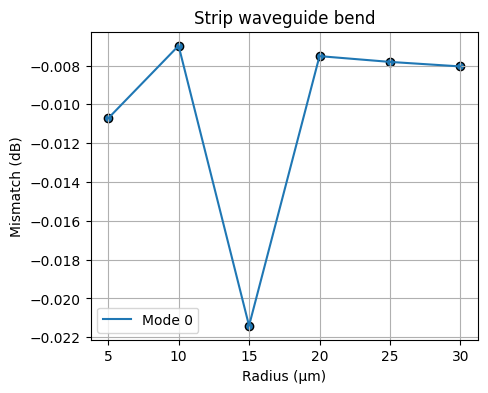

In [290]:
plt.figure(figsize=(5,4))

plt.scatter(radii, 10 * np.log10(mismatch[:,0]),edgecolors='k')
plt.plot(radii, 10 * np.log10(mismatch[:,0]),label=f'Mode {0}')
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.grid()
plt.legend()

There are some issues, so we'll upgrade de grid resolution.

In [291]:
%%capture

bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=500*nm,
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=70, 
    bend_radius=5, # Bend radius
)

radii = np.linspace(5.0, 30, 6)
mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)

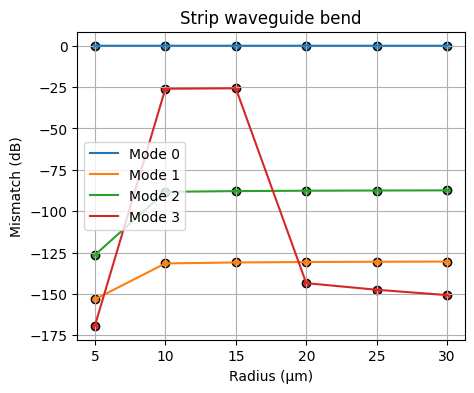

In [292]:
plt.figure(figsize=(5,4))
for k in range(mismatch.shape[1]): # k es el nº del mode
    plt.scatter(radii, 10 * np.log10(mismatch[:,k]),edgecolors='k')
    plt.plot(radii, 10 * np.log10(mismatch[:,k]),label=f'Mode {k}')
# plt.plot(radii, 10 * np.log10(mismatch_TE0), 'bo-', label='Mode TE0')
# plt.plot(radii, 10 * np.log10(mismatch_TM0), 'rs-', label='Mode TM0')
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.grid()
plt.legend()

Regarding the tm and te fraction analysis for a R variation, we'll also do here the re-ordering of the modes' fisrt data point (R=5 $\mu m$). However, we will disregard the meaning of this point at the final graphs because we have seen that it's not a guided mode.

In [293]:
mismatch_TE0 = mismatch[:,0]
mismatch_TM0 = mismatch[:,1]
print(mismatch_TM0)
mismatch_TM0[0] = mismatch[0,3]
print(mismatch_TM0)

[4.69187232e-16 6.92332200e-14 7.93036151e-14 8.44864815e-14
 8.76417978e-14 8.97822838e-14]
[1.18768874e-17 6.92332200e-14 7.93036151e-14 8.44864815e-14
 8.76417978e-14 8.97822838e-14]


#### Propagation Loss - Si

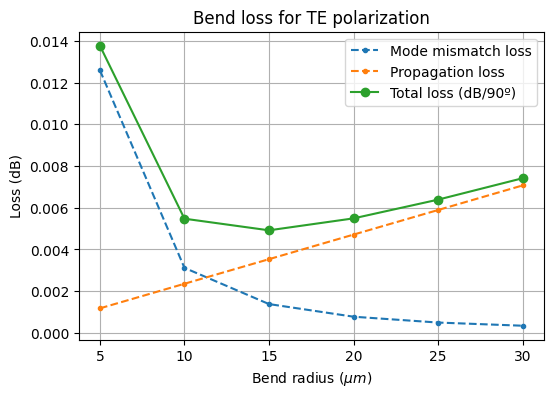

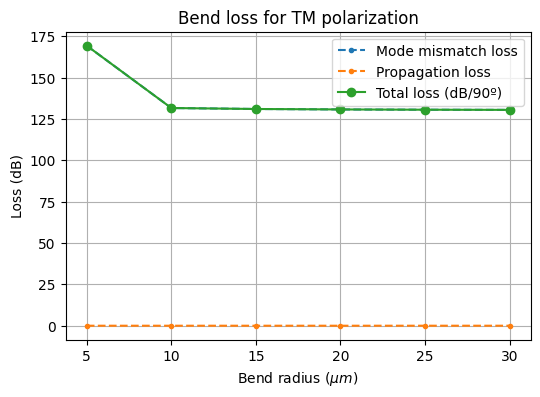

In [295]:
dB_cm = 1.5  # dB/cm Technology loss
length = 0.5 * np.pi * radii * 1e-6 # m
propagation_loss = dB_cm * length * 1e2 # m

plt.figure(figsize=(6,4))
plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch_TE0), ".--", label="Mode mismatch loss")
plt.plot(radii, propagation_loss, ".--", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_TE0), "o-", label="Total loss (dB/90º)")
plt.xlabel(r"Bend radius ($\mu m$)")
plt.ylabel("Loss (dB)")
plt.grid()
plt.legend()

plt.figure(figsize=(6,4))
plt.title("Bend loss for TM polarization")
plt.plot(radii, -10 * np.log10(mismatch_TM0), ".--", label="Mode mismatch loss")
plt.plot(radii, propagation_loss, ".--", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_TM0), "o-", label="Total loss (dB/90º)")
plt.xlabel(r"Bend radius ($\mu m$)")
plt.ylabel("Loss (dB)")
plt.grid()
plt.legend()
# plt.ylim(0,0.40)

Let's lower it a little.

In [296]:
%%capture

bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=500*nm,
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=40, 
    bend_radius=5, # Bend radius
)

radii = np.linspace(5.0, 30, 6)
mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)

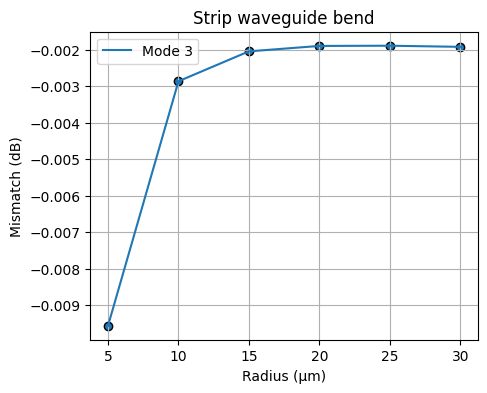

In [298]:
plt.figure(figsize=(5,4))
plt.scatter(radii, 10 * np.log10(mismatch[:,0]),edgecolors='k')
plt.plot(radii, 10 * np.log10(mismatch[:,0]),label=f'Mode {k}')

plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.grid()
plt.legend()

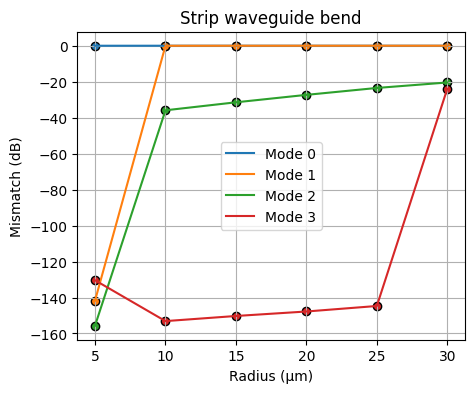

In [297]:
plt.figure(figsize=(5,4))
for k in range(mismatch.shape[1]): # k es el nº del mode
    plt.scatter(radii, 10 * np.log10(mismatch[:,k]),edgecolors='k')
    plt.plot(radii, 10 * np.log10(mismatch[:,k]),label=f'Mode {k}')
# plt.plot(radii, 10 * np.log10(mismatch_TE0), 'bo-', label='Mode TE0')
# plt.plot(radii, 10 * np.log10(mismatch_TM0), 'rs-', label='Mode TM0')
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.grid()
plt.legend()

In [299]:
mismatch_TE0 = mismatch[:,0]
mismatch_TM0 = mismatch[:,1]
print(mismatch_TM0)
mismatch_TM0[0] = mismatch[0,3]
print(mismatch_TM0)

[6.68688970e-15 9.93507098e-01 9.97766331e-01 9.98976040e-01
 9.99451842e-01 9.99669695e-01]
[9.09062177e-14 9.93507098e-01 9.97766331e-01 9.98976040e-01
 9.99451842e-01 9.99669695e-01]


(0.0, 0.05)

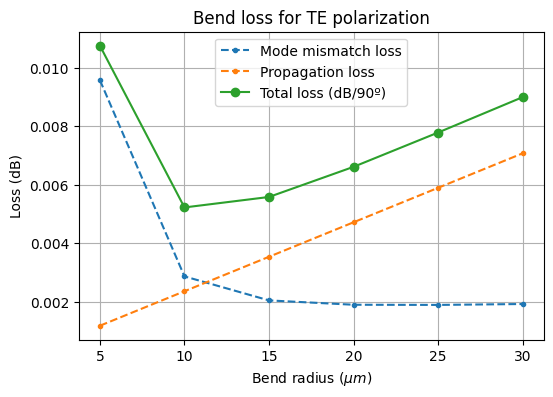

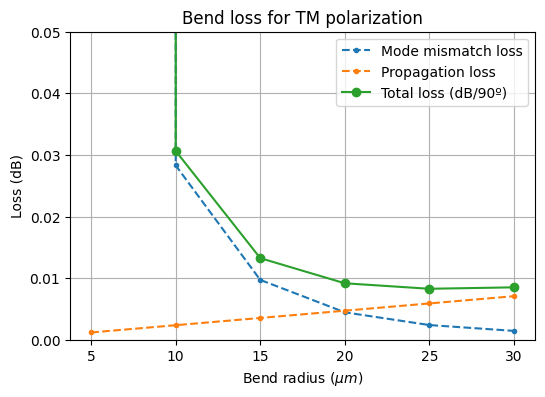

In [ ]:
dB_cm = 1.5  # dB/cm Technology loss
length = 0.5 * np.pi * radii * 1e-6 # m
propagation_loss = dB_cm * length * 1e2 # m

plt.figure(figsize=(6,4))
plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch_TE0), ".--", label="Mode mismatch loss")
plt.plot(radii, propagation_loss, ".--", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_TE0), "o-", label="Total loss (dB/90º)")
plt.xlabel(r"Bend radius ($\mu m$)")
plt.ylabel("Loss (dB)")
plt.grid()
plt.legend()

plt.figure(figsize=(6,4))
plt.title("Bend loss for TM polarization")
plt.plot(radii, -10 * np.log10(mismatch_TM0), ".--", label="Mode mismatch loss")
plt.plot(radii, propagation_loss, ".--", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_TM0), "o-", label="Total loss (dB/90º)")
plt.xlabel(r"Bend radius ($\mu m$)")
plt.ylabel("Loss (dB)")
plt.grid()
plt.legend()
plt.ylim(0,0.05)

## Grading

LO.1. 2 Point <br> 
LO.2. 1 Points <br> 
LO.3. 3 Point <br> 
LO.4. 1 Points <br> 
**Total 7 Points** <br>
Extra (Up to) 3 Points
